# Semana 1
 Análise Exploratória e Engenharia de Dados
 - Extraia as informações brutas do dataset do SideSeeing, separando as sequências de vídeo, os logs de GPS e os sinais do acelerômetro e giroscópio.  - Abra o seu ambiente Python (seja no terminal do Ubuntu ou pelo Carnets no seu iPad) e use o Matplotlib para gerar gráficos exploratórios que mostrem o comportamento dos sensores ao longo do tempo.
 - Escreva a seção de Metodologia do relatório detalhando exclusivamente as lógicas de organização, limpeza e estruturação desses dados brutos para torná-los utilizáveis.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import glob
import os
import scipy

In [ ]:
folder = "/content/drive/MyDrive/2025_Auditoria_Calcadas/00_dados_originais/MultiSensor/"

lista_sensor3 = []

for dia in os.listdir(folder): #lista as subpastas
  caminho_dia = os.path.join(folder, dia) #
  if os.path.isdir(caminho_dia): #verifica se é uma pasta
    for dado in os.listdir(caminho_dia): #pega a pasta do dia
      caminho_dado = os.path.join(caminho_dia, dado)
      if os.path.isdir(caminho_dado):
        for sensor in os.listdir(caminho_dado): #olha os sensores
          if sensor == "sensors.three.csv":
            caminho_arquivo = os.path.join(caminho_dado, sensor)
            df = pd.read_csv(caminho_arquivo)
            df["dia_rota"] = dia
            df['dado_rota'] = dado
            df['sensor'] = sensor
            lista_sensor3.append(df)
      else:
        print(f"{dado} não é uma pasta")
  else:
    print(f"{dia} não é uma pasta")
print(f"foram encontrados {len(lista_sensor3)} arquivos")







foram encontrados 216 arquivos


In [ ]:
display(lista_sensor3[0])

,timestamp_nano,datetime_utc,name,axis_x,axis_y,axis_z,accuracy,dia_rota,dado_rota,sensor
0,684319996180666,2025-11-11T11:45:36.505Z,lsm6dsv LSM6DSO Gyroscope Non-wakeup,0.050854,0.002596,0.017104,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
1,684320000556187,2025-11-11T11:45:36.510Z,lsm6dsv LSM6DSV Accelerometer Non-wakeup,9.690931,0.406182,2.542972,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
2,684320027582853,2025-11-11T11:45:36.536Z,lsm6dsv LSM6DSO Gyroscope Non-wakeup,0.034056,-0.049022,0.014050,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
3,684320013225457,2025-11-11T11:45:36.523Z,AK09918 Magnetometer,1.331250,-18.825000,17.400002,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
4,684320021130041,2025-11-11T11:45:36.530Z,lsm6dsv LSM6DSV Accelerometer Non-wakeup,9.678370,0.375075,2.271985,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
...,...,...,...,...,...,...,...,...,...,...
81612,684754173225350,2025-11-11T11:52:50.683Z,AK09918 Magnetometer,-11.737500,-13.537500,13.331250,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
81613,684754176118215,2025-11-11T11:52:50.686Z,lsm6dsv LSM6DSV Accelerometer Non-wakeup,9.728619,-0.123829,2.449054,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
81614,684754169221444,2025-11-11T11:52:50.679Z,lsm6dsv LSM6DSO Gyroscope Non-wakeup,0.036041,0.025809,0.033139,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
81615,684754186948423,2025-11-11T11:52:50.696Z,lsm6dsv LSM6DSV Accelerometer Non-wakeup,9.717851,-0.174078,2.557329,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv


In [ ]:
display(lista_sensor3)

[        timestamp_nano              datetime_utc  \
 0      684319996180666  2025-11-11T11:45:36.505Z   
 1      684320000556187  2025-11-11T11:45:36.510Z   
 2      684320027582853  2025-11-11T11:45:36.536Z   
 3      684320013225457  2025-11-11T11:45:36.523Z   
 4      684320021130041  2025-11-11T11:45:36.530Z   
 ...                ...                       ...   
 81612  684754173225350  2025-11-11T11:52:50.683Z   
 81613  684754176118215  2025-11-11T11:52:50.686Z   
 81614  684754169221444  2025-11-11T11:52:50.679Z   
 81615  684754186948423  2025-11-11T11:52:50.696Z   
 81616  684754193225350  2025-11-11T11:52:50.703Z   
 
                                            name     axis_x     axis_y  \
 0          lsm6dsv LSM6DSO Gyroscope Non-wakeup   0.050854   0.002596   
 1      lsm6dsv LSM6DSV Accelerometer Non-wakeup   9.690931   0.406182   
 2          lsm6dsv LSM6DSO Gyroscope Non-wakeup   0.034056  -0.049022   
 3                          AK09918 Magnetometer   1.331250 -18.82

# Vamos separar os dados

# Preparar os datasets
Vamos criar um dataframe para os dados do giroscópio, acelerômetro e magnômetro




In [ ]:
df_total = pd.concat(lista_sensor3, ignore_index=True) #concatena todos os dados em um dado só
df_giro = df_total[df_total["name"].str.contains("Gyroscope", case=False, na=False)].copy() #faz uma copia de todos que na coluna name tem "Gyroscope"
df_acel = df_total[df_total["name"].str.contains("Accelerometer", case=False, na=False)].copy()
df_mag = df_total[df_total["name"].str.contains("Magnetometer", case=False, na=False)].copy()
display(df_giro)
display(df_acel)
display(df_mag)

,timestamp_nano,datetime_utc,name,axis_x,axis_y,axis_z,accuracy,dia_rota,dado_rota,sensor
0,684319996180666,2025-11-11T11:45:36.505Z,lsm6dsv LSM6DSO Gyroscope Non-wakeup,0.050854,0.002596,0.017104,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
2,684320027582853,2025-11-11T11:45:36.536Z,lsm6dsv LSM6DSO Gyroscope Non-wakeup,0.034056,-0.049022,0.014050,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
6,684320058984885,2025-11-11T11:45:36.567Z,lsm6dsv LSM6DSO Gyroscope Non-wakeup,0.025656,-0.018021,-0.001069,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
11,684320090387072,2025-11-11T11:45:36.600Z,lsm6dsv LSM6DSO Gyroscope Non-wakeup,0.011912,-0.014050,0.002749,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
17,684320121789155,2025-11-11T11:45:36.631Z,lsm6dsv LSM6DSO Gyroscope Non-wakeup,0.004734,0.005650,0.000764,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
...,...,...,...,...,...,...,...,...,...,...
18362169,103311163929951,2025-11-11T10:33:08.501Z,lsm6dso LSM6DSO Gyroscope Non-wakeup,-0.004581,0.026420,-0.002443,3,D3P2,2025-11-11-07-25-15-976,sensors.three.csv
18362188,103311264893076,2025-11-11T10:33:08.602Z,lsm6dso LSM6DSO Gyroscope Non-wakeup,-0.003054,0.037263,0.010690,3,D3P2,2025-11-11-07-25-15-976,sensors.three.csv
18362205,103311365856357,2025-11-11T10:33:08.703Z,lsm6dso LSM6DSO Gyroscope Non-wakeup,0.000916,0.035736,0.014050,3,D3P2,2025-11-11-07-25-15-976,sensors.three.csv
18362223,103311466819743,2025-11-11T10:33:08.804Z,lsm6dso LSM6DSO Gyroscope Non-wakeup,-0.024740,0.042150,0.003054,3,D3P2,2025-11-11-07-25-15-976,sensors.three.csv


,timestamp_nano,datetime_utc,name,axis_x,axis_y,axis_z,accuracy,dia_rota,dado_rota,sensor
1,684320000556187,2025-11-11T11:45:36.510Z,lsm6dsv LSM6DSV Accelerometer Non-wakeup,9.690931,0.406182,2.542972,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
4,684320021130041,2025-11-11T11:45:36.530Z,lsm6dsv LSM6DSV Accelerometer Non-wakeup,9.678370,0.375075,2.271985,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
5,684320041703843,2025-11-11T11:45:36.551Z,lsm6dsv LSM6DSV Accelerometer Non-wakeup,9.712467,0.379861,2.158924,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
7,684320062277593,2025-11-11T11:45:36.572Z,lsm6dsv LSM6DSV Accelerometer Non-wakeup,9.552148,0.409771,2.338386,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
8,684320079959155,2025-11-11T11:45:36.589Z,lsm6dsv LSM6DSV Accelerometer Non-wakeup,9.476774,0.456431,2.248655,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
...,...,...,...,...,...,...,...,...,...,...
18362236,103311596058128,2025-11-11T10:33:08.935Z,lsm6dso LSM6DSO Accelerometer Non-wakeup,9.777672,0.281157,1.737788,3,D3P2,2025-11-11-07-25-15-976,sensors.three.csv
18362238,103311605789378,2025-11-11T10:33:08.943Z,lsm6dso LSM6DSO Accelerometer Non-wakeup,9.687941,0.302094,1.633700,3,D3P2,2025-11-11-07-25-15-976,sensors.three.csv
18362240,103311615520889,2025-11-11T10:33:08.953Z,lsm6dso LSM6DSO Accelerometer Non-wakeup,9.684352,0.278166,1.508076,3,D3P2,2025-11-11-07-25-15-976,sensors.three.csv
18362242,103311625252295,2025-11-11T10:33:08.963Z,lsm6dso LSM6DSO Accelerometer Non-wakeup,9.639486,0.202194,1.356731,3,D3P2,2025-11-11-07-25-15-976,sensors.three.csv


,timestamp_nano,datetime_utc,name,axis_x,axis_y,axis_z,accuracy,dia_rota,dado_rota,sensor
3,684320013225457,2025-11-11T11:45:36.523Z,AK09918 Magnetometer,1.331250,-18.825000,17.400002,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
9,684320093225457,2025-11-11T11:45:36.602Z,AK09918 Magnetometer,0.393750,-18.225000,17.906250,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
13,684320113225457,2025-11-11T11:45:36.623Z,AK09918 Magnetometer,-0.393750,-16.106250,16.481250,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
19,684320133225457,2025-11-11T11:45:36.643Z,AK09918 Magnetometer,0.787500,-17.343750,14.700001,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
21,684320153225457,2025-11-11T11:45:36.662Z,AK09918 Magnetometer,1.968750,-15.693750,14.531251,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
...,...,...,...,...,...,...,...,...,...,...
18362228,103311545214014,2025-11-11T10:33:08.883Z,AK09918 Magnetometer,21.168750,13.087501,5.043750,3,D3P2,2025-11-11-07-25-15-976,sensors.three.csv
18362231,103311565214014,2025-11-11T10:33:08.903Z,AK09918 Magnetometer,21.318750,12.918751,5.287500,3,D3P2,2025-11-11-07-25-15-976,sensors.three.csv
18362234,103311585214014,2025-11-11T10:33:08.923Z,AK09918 Magnetometer,21.393751,12.675000,4.818750,3,D3P2,2025-11-11-07-25-15-976,sensors.three.csv
18362237,103311605214014,2025-11-11T10:33:08.943Z,AK09918 Magnetometer,21.037500,12.562501,4.631250,3,D3P2,2025-11-11-07-25-15-976,sensors.three.csv


In [ ]:
df_sobrou = df_total[(~ df_total["name"].str.contains("Gyroscope", case=False, na=False)) & (~ df_total["name"].str.contains("Accelerometer", case=False, na=False)) & (~ df_total["name"].str.contains("Magnometer", case=False, na=False))].copy()
display(df_sobrou) #só para checar quais dados existiam alem dos usados



,timestamp_nano,datetime_utc,name,axis_x,axis_y,axis_z,accuracy,dia_rota,dado_rota,sensor
3,684320013225457,2025-11-11T11:45:36.523Z,AK09918 Magnetometer,1.331250,-18.825000,17.400002,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
9,684320093225457,2025-11-11T11:45:36.602Z,AK09918 Magnetometer,0.393750,-18.225000,17.906250,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
13,684320113225457,2025-11-11T11:45:36.623Z,AK09918 Magnetometer,-0.393750,-16.106250,16.481250,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
14,684320027337645,2025-11-11T11:45:36.536Z,linear_acceleration,-0.105968,-0.068265,-0.126486,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
19,684320133225457,2025-11-11T11:45:36.643Z,AK09918 Magnetometer,0.787500,-17.343750,14.700001,3,D3P3,2025-11-11-08-45-36-473,sensors.three.csv
...,...,...,...,...,...,...,...,...,...,...
18362234,103311585214014,2025-11-11T10:33:08.923Z,AK09918 Magnetometer,21.393751,12.675000,4.818750,3,D3P2,2025-11-11-07-25-15-976,sensors.three.csv
18362237,103311605214014,2025-11-11T10:33:08.943Z,AK09918 Magnetometer,21.037500,12.562501,4.631250,3,D3P2,2025-11-11-07-25-15-976,sensors.three.csv
18362241,103311625214014,2025-11-11T10:33:08.964Z,AK09918 Magnetometer,21.000000,12.618751,4.556250,3,D3P2,2025-11-11-07-25-15-976,sensors.three.csv
18362243,103311534932972,2025-11-11T10:33:08.872Z,linear_acceleration,0.016251,0.032347,-0.062882,3,D3P2,2025-11-11-07-25-15-976,sensors.three.csv


# Giroscópio

Vamos plotar exemplos do giroscópio em rotas

#

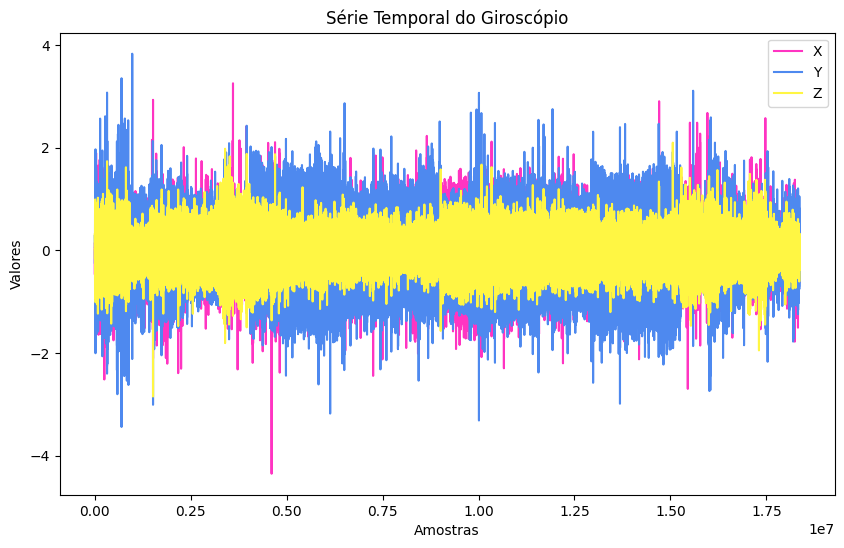

In [ ]:
plt.figure(figsize=(10, 6)) #cria a figura

#para plotar os eixos:
plt.plot(df_giro["axis_x"], color="#FF34C2", label="X", alpha=1)
plt.plot(df_giro["axis_y"], color='#4E89EF', label="Y", alpha=1)
plt.plot(df_giro["axis_z"], color='#FFF643', label="Z", alpha=1)

plt.title("Série Temporal do Giroscópio")
plt.xlabel("Amostras")
plt.ylabel("Valores")
plt.legend()
plt.show()

Rotas disponíveis: ['D3P3' 'D4P4' 'D2P4' 'D4P1' 'D2P3' 'D4P3' 'D3P4' 'D2P2' 'D1P4' 'D4P2'
 'D1P3' 'D1P2' 'D1P1' 'D2P1' 'D3P1' 'D3P2']


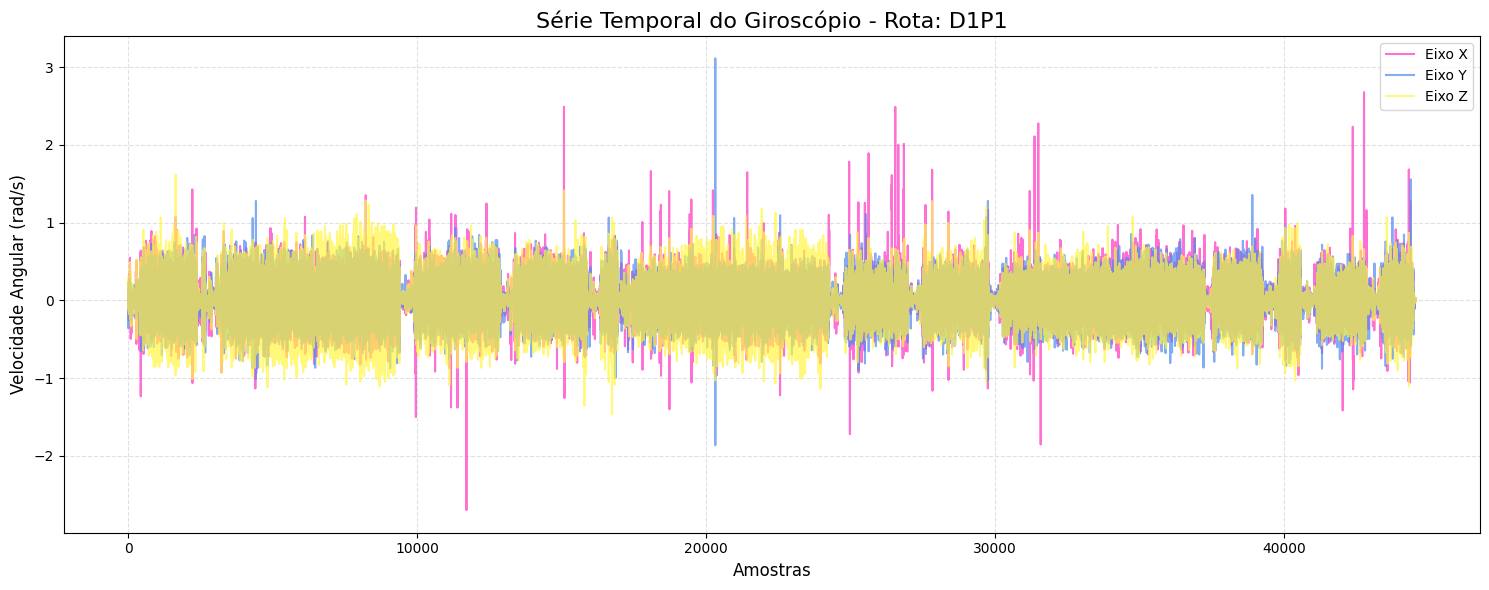

In [ ]:
# 1. Primeiro, vamos ver quais são os nomes das rotas (dias) que existem no seu dataset
print("Rotas disponíveis:", df_giro['dia_rota'].unique())

# 2. Copie um dos nomes que apareceu no print acima e coloque dentro das aspas abaixo
# Exemplo: se apareceu 'dia_01', substitua 'NOME_DA_SUA_PASTA' por 'dia_01'
nome_da_rota_escolhida = 'D1P1'

# 3. Fazemos o filtro usando a coluna dia_rota e criamos uma cópia independente
df_giro_uma_rota = df_giro[df_giro['dia_rota'] == nome_da_rota_escolhida].copy()

# 4. Agora plotamos usando os códigos hexadecimais que aprendemos!
plt.figure(figsize=(15, 6))

plt.plot(df_giro_uma_rota['axis_x'].values, label='Eixo X', color='#FF34C2', alpha=0.7)
plt.plot(df_giro_uma_rota['axis_y'].values, label='Eixo Y', color='#4E89EF', alpha=0.7)
plt.plot(df_giro_uma_rota['axis_z'].values, label='Eixo Z', color='#FFF643', alpha=0.7)

# Adicionando o nome da rota no título para o seu relatório ficar bem documentado
plt.title(f'Série Temporal do Giroscópio - Rota: {nome_da_rota_escolhida}', fontsize=16)
plt.xlabel('Amostras', fontsize=12)
plt.ylabel('Velocidade Angular (rad/s)', fontsize=12)

plt.legend(loc='upper right')
plt.grid(True, color='#E0E0E0', linestyle='--')
plt.tight_layout()
plt.show()



# Acelerômetro

Rotas disponíveis: ['D3P3' 'D4P4' 'D2P4' 'D4P1' 'D2P3' 'D4P3' 'D3P4' 'D2P2' 'D1P4' 'D4P2'
 'D1P3' 'D1P2' 'D1P1' 'D2P1' 'D3P1' 'D3P2']


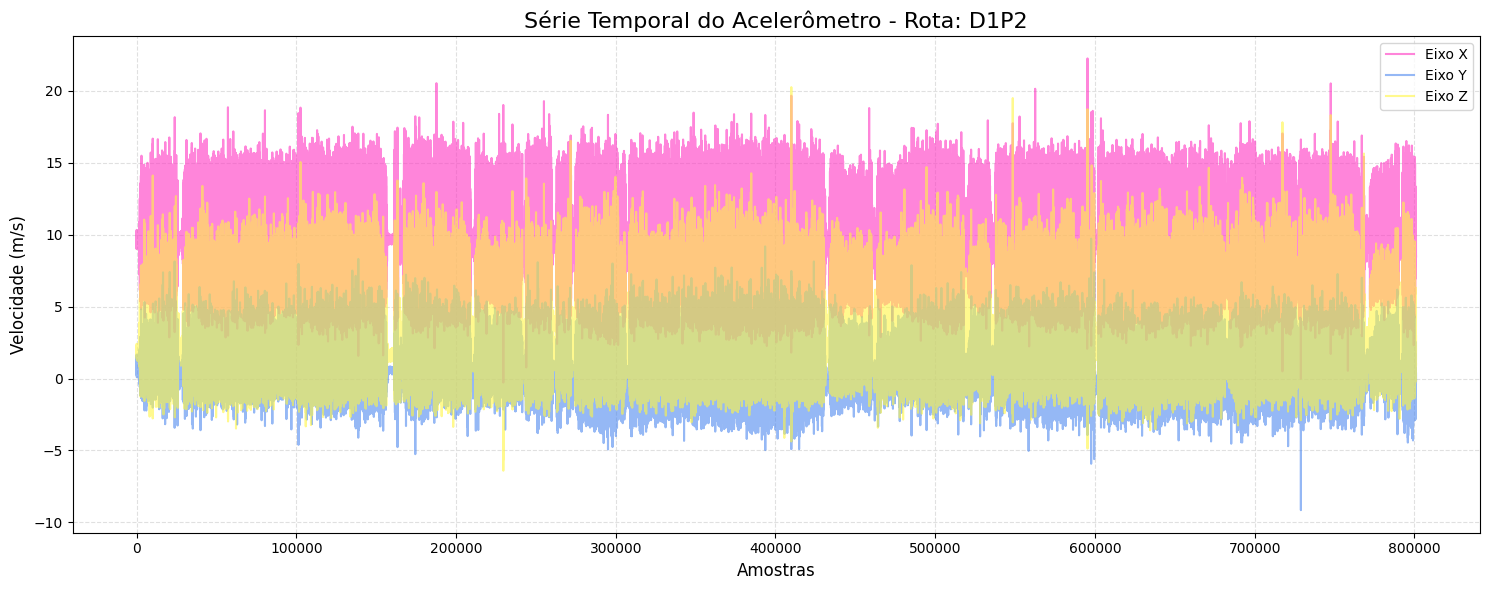

In [ ]:
# 1. Primeiro, vamos ver quais são os nomes das rotas (dias) que existem no seu dataset
print("Rotas disponíveis:", df_acel['dia_rota'].unique())

# 2. Copie um dos nomes que apareceu no print acima e coloque dentro das aspas abaixo
# Exemplo: se apareceu 'dia_01', substitua 'NOME_DA_SUA_PASTA' por 'dia_01'
nome_da_rota_escolhida = 'D1P2'

# 3. Fazemos o filtro usando a coluna dia_rota e criamos uma cópia independente
df_acel_uma_rota = df_acel[df_acel['dia_rota'] == nome_da_rota_escolhida].copy()

# 4. Agora plotamos usando os códigos hexadecimais que aprendemos!
plt.figure(figsize=(15, 6))

plt.plot(df_acel_uma_rota['axis_x'].values, label='Eixo X', color='#ff34c2', alpha=0.6)
plt.plot(df_acel_uma_rota['axis_y'].values, label='Eixo Y', color='#4E89EF', alpha=0.6)
plt.plot(df_acel_uma_rota['axis_z'].values, label='Eixo Z', color='#FFF643', alpha=0.6)

# Adicionando o nome da rota no título para o seu relatório ficar bem documentado
plt.title(f'Série Temporal do Acelerômetro - Rota: {nome_da_rota_escolhida}', fontsize=16)
plt.xlabel('Amostras', fontsize=12)
plt.ylabel('Velocidade (m/s)', fontsize=12)

plt.legend(loc='upper right')
plt.grid(True, color='#E0E0E0', linestyle='--')
plt.tight_layout()
plt.show()

# Análise dos dois juntos

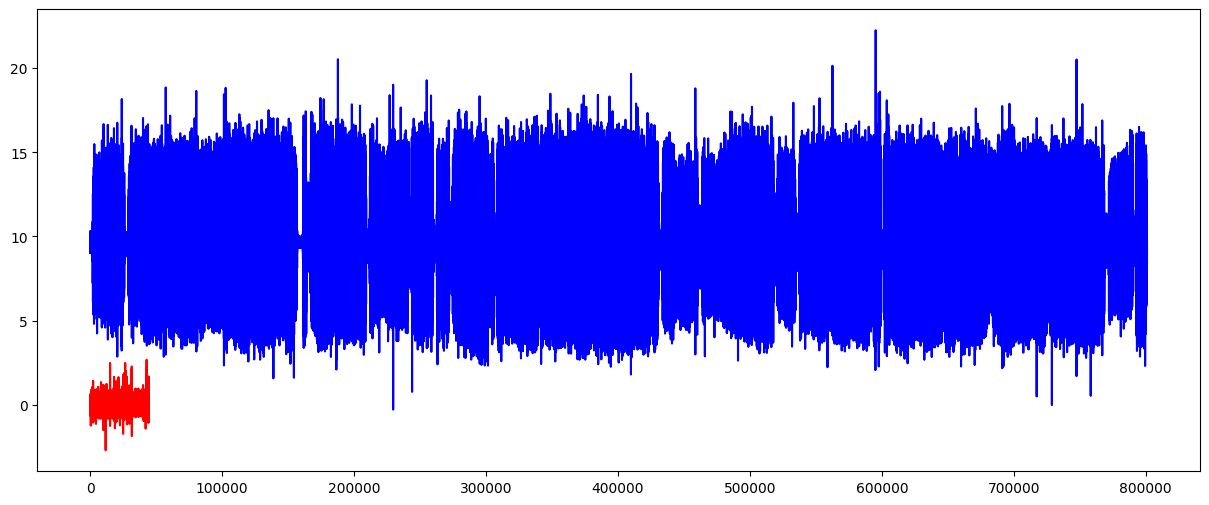

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(df_giro_uma_rota['axis_x'].values, label='Giroscópio - Eixo X', color='red', alpha=1)
plt.plot(df_acel_uma_rota['axis_x'].values, label='Acelerômetro - Eixo X', color='blue', alpha=1)


Como visto no ultimo plot, os sensores tem diferentes quantidade de captura por um determinado tempo. Por causa disso vou utilizar o timestamp para alinhá-los

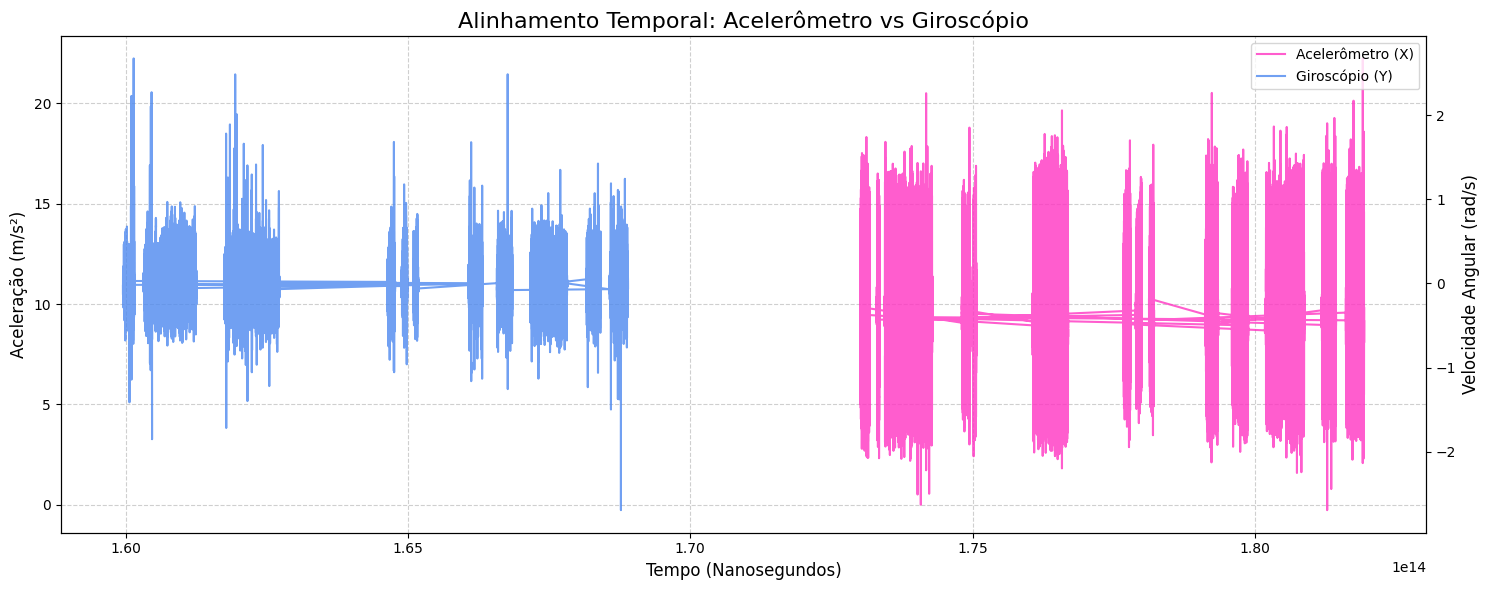

In [ ]:
fig, ax1 = plt.subplots(figsize=(15,6))
coluna_tempo = 'timestamp_nano' #coluna do timestamp

# Aqui passamos a coluna de tempo para o X e a coluna axis_x para o Y
ax1.plot(df_acel_uma_rota[coluna_tempo], df_acel_uma_rota['axis_x'], label='Acelerômetro (X)', color='#FF34C2', alpha=0.8)
ax1.set_xlabel('Tempo (Nanosegundos)', fontsize=12)
ax1.set_ylabel('Aceleração (m/s²)', fontsize=12)
ax1.tick_params(axis='y')

ax2 = ax1.twinx() #isso cria um eixo y "preso" ao eixo x


ax2.plot(df_giro_uma_rota[coluna_tempo], df_giro_uma_rota['axis_x'], label='Giroscópio (Y)', color="#4E89EF", alpha=0.8)
ax2.set_xlabel('Tempo (Nanosegundos)', fontsize=12)
ax2.set_ylabel('Velocidade Angular (rad/s)', fontsize=12)
ax2.tick_params(axis='y')


plt.title('Alinhamento Temporal: Acelerômetro vs Giroscópio', fontsize=16)
ax1.grid(True, linestyle='--', alpha=0.6)

# Como temos dois 'ax' separados, juntamos as legendas para ficarem em uma caixinha só
linhas_1, labels_1 = ax1.get_legend_handles_labels()
linhas_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(linhas_1 + linhas_2, labels_1 + labels_2, loc='upper right')

# tight_layout evita que os textos das bordas cortem
plt.tight_layout()
plt.show()


Hmm, curioso. eu vou concatenar de novo o D1P1 para ver se arruma.


Rotas disponíveis: ['2025-11-11-08-45-36-473' '2025-11-11-08-05-08-890'
 '2025-11-11-08-09-29-004' '2025-11-11-08-23-15-631'
 '2025-11-11-08-36-03-518' '2025-11-11-07-59-30-060'
 '2025-11-11-10-18-34-672' '2025-11-11-07-45-23-045'
 '2025-11-16-09-30-29-941' '2025-11-16-09-51-57-695'
 '2025-11-16-09-46-05-629' '2025-11-16-09-35-26-991'
 '2025-11-16-08-51-35-779' '2025-11-16-08-57-28-554'
 '2025-11-16-08-15-21-894' '2025-11-16-08-45-04-455'
 '2025-11-16-09-23-49-359' '2025-11-16-09-14-45-623'
 '2025-11-16-09-09-55-541' '2025-11-16-08-20-07-573'
 '2025-11-16-07-40-20-234' '2025-11-16-07-55-24-946'
 '2025-11-16-08-04-08-484' '2025-11-16-07-17-03-512'
 '2025-11-16-06-59-50-151' '2025-11-10-09-25-21-295'
 '2025-11-10-09-32-36-682' '2025-11-10-09-32-03-969'
 '2025-11-10-09-15-25-210' '2025-11-10-08-13-02-339'
 '2025-11-10-07-41-43-471' '2025-11-10-07-53-41-725'
 '2025-11-10-07-29-43-918' '2025-11-10-08-57-26-451'
 '2025-11-10-07-21-03-797' '2025-11-10-07-11-59-908'
 '2025-11-10-07-58-25-203' 

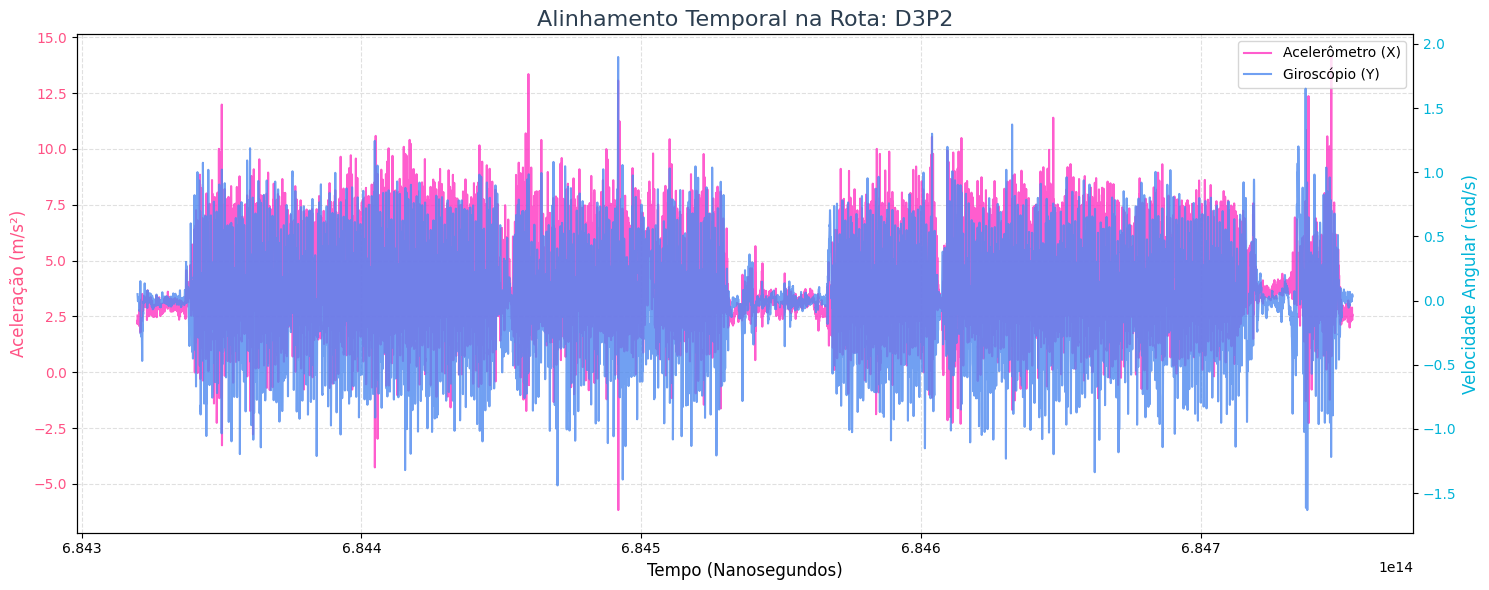

In [ ]:
print("Rotas disponíveis:", df_acel['dado_rota'].unique())

dado = '2025-11-11-08-45-36-473'

df_giro_dia = df_giro[df_giro["dado_rota"] == dado].copy()
df_acel_dia = df_acel[df_acel["dado_rota"] == dado].copy()

# ==========================================
# 2. PLOTAGEM COM EIXOS DUPLOS (SEM PULOS)
# ==========================================
fig, ax1 = plt.subplots(figsize=(15, 6))
coluna_tempo = 'timestamp_nano'

# Acelerômetro (Esquerda)
ax1.plot(df_acel_dia[coluna_tempo], df_acel_dia['axis_z'],
         label='Acelerômetro (X)', color='#FF34C2', alpha=0.8) # Rosa
ax1.set_xlabel('Tempo (Nanosegundos)', fontsize=12)
ax1.set_ylabel('Aceleração (m/s²)', fontsize=12, color='#FF5285')
ax1.tick_params(axis='y', labelcolor='#FF5285')

# Giroscópio (Direita)
ax2 = ax1.twinx()
ax2.plot(df_giro_dia[coluna_tempo], df_giro_dia['axis_x'],
         label='Giroscópio (Y)', color='#4E89EF', alpha=0.8) # Azul
ax2.set_ylabel('Velocidade Angular (rad/s)', fontsize=12, color='#00B4D8')
ax2.tick_params(axis='y', labelcolor='#00B4D8')

# Estética
plt.title(f'Alinhamento Temporal na Rota: {dia}', fontsize=16, color='#2C3E50')
ax1.grid(True, color='#E0E0E0', linestyle='--')

linhas_1, labels_1 = ax1.get_legend_handles_labels()
linhas_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(linhas_1 + linhas_2, labels_1 + labels_2, loc='upper right')

plt.tight_layout()
plt.show()

# Semana 2

1. Pedômetro Simples: Usar o eixo vertical do acelerômetro e a função find_peaks para calcular a contagem e cadência de passos.


2. Escrita da Crítica Científica: Redigir o parágrafo concluindo que o celular no peito age como amortecedor, impossibilitando achar falhas milimétricas.

Total de Picos (Lado A): 2
Total de Vales (Lado B): 2

Índices de todas as curvas em ordem cronológica:
[ 5446 13234 13238 13253]


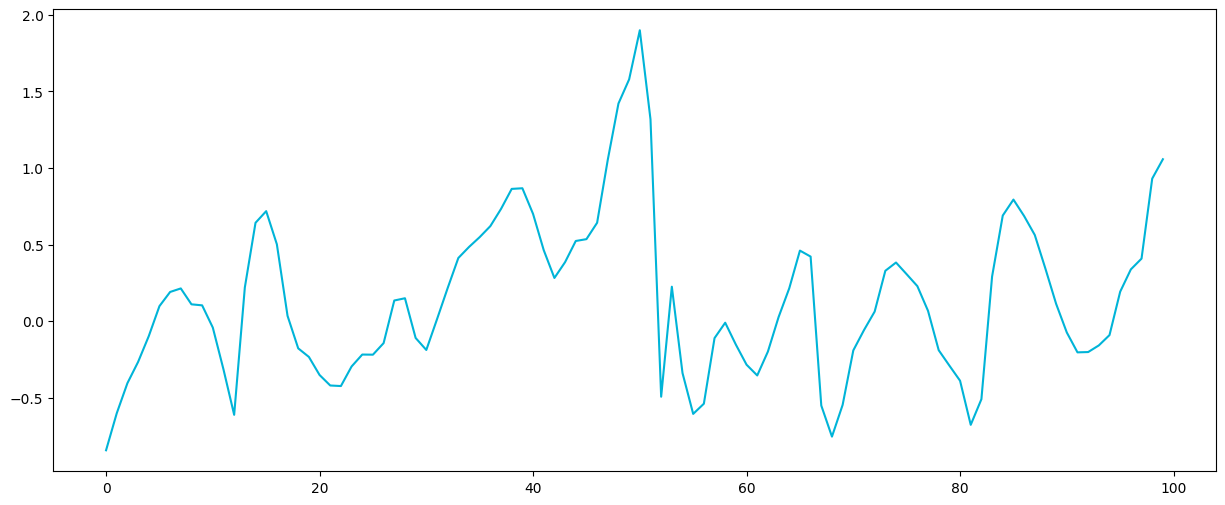

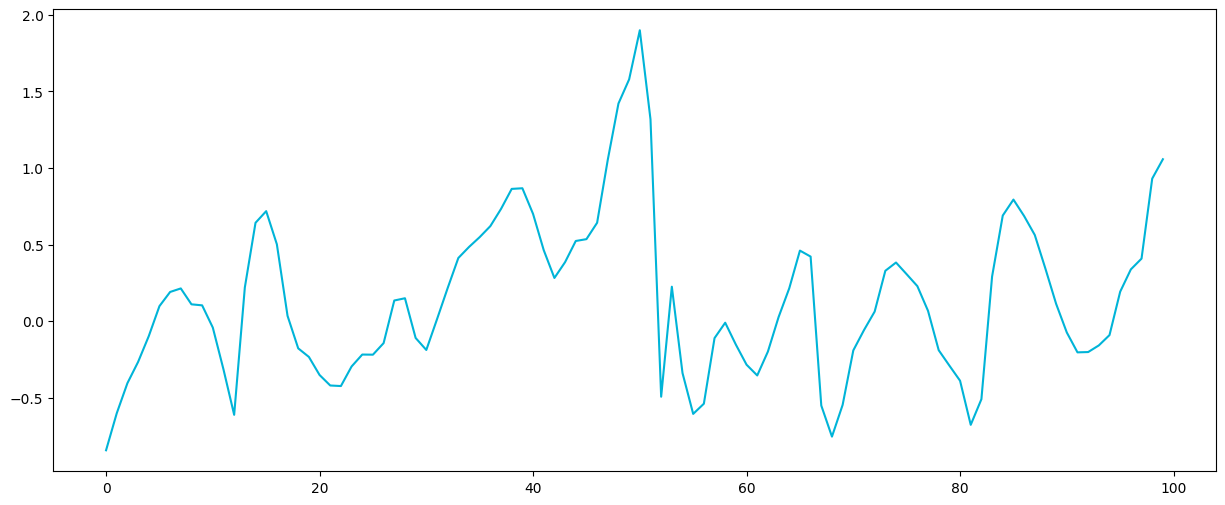

In [ ]:
# Teste de find_peaks
picos, info_picos = scipy.signal.find_peaks(df_giro_dia['axis_x'].values, height=np.pi/2) #pega os picos
vales, info_vales = scipy.signal.find_peaks(-df_giro_dia['axis_x'].values, height=np.pi/2) #pega os vales
linha_curva = np.concatenate((picos, vales)) #une eles
linha_curva.sort()
print(f"Total de Picos (Lado A): {len(picos)}")
print(f"Total de Vales (Lado B): {len(vales)}")
print("\nÍndices de todas as curvas em ordem cronológica:")
print(linha_curva)

#ok, o que precisamos fazer agora é plotar o intervalo de pico.

tamanho_total = len(df_giro_dia)
pico = linha_curva[0] #vamos testar primeiro com 1 pico só
inicio = max(0, pico - 50)
fim = min(tamanho_total, pico + 50)
intervalo = df_giro_dia['axis_x'].values[inicio:fim]
plt.figure(figsize=(15,6))
plt.plot(intervalo, color='#00B4D8')
plt.show()

#Vamos plotar outros 2 exempl

tamanho_total = len(df_giro_dia)
pico = linha_curva[0] #vamos testar primeiro com 1 pico só
inicio = max(0, pico - 50)
fim = min(tamanho_total, pico + 50)
intervalo = df_giro_dia['axis_x'].values[inicio:fim]
plt.figure(figsize=(15,6))
plt.plot(intervalo, color='#00B4D8')
plt.show()





In [ ]:
def mesclar_curvas_proximas(indices_curvas, janela_amostras=20):
    """
    Agrupa índices de curva que estão muito próximos entre si (mesmo evento
    físico detectado como pico + vale separados) num único ponto representativo.
    """
    if len(indices_curvas) == 0:
        return indices_curvas

    indices_curvas = np.sort(indices_curvas)
    grupos = [[indices_curvas[0]]]

    for idx in indices_curvas[1:]:
        if idx - grupos[-1][-1] <= janela_amostras:
            grupos[-1].append(idx)  # está perto do último grupo, junta
        else:
            grupos.append([idx])  # está longe, começa um grupo novo

    # Representa cada grupo pelo índice médio (ou pelo primeiro, se preferir)
    return np.array([int(np.mean(g)) for g in grupos])

In [ ]:
linha_curva = np.concatenate((picos, vales))
linha_curva.sort()
linha_curva = mesclar_curvas_proximas(linha_curva, janela_amostras=20)  # nova linha

Vamos tentar plotar agora os dados de gps

In [ ]:
gpkg_path = "/content/drive/MyDrive/2025_Auditoria_Calcadas/01_dados_processados/03_gpkg_shapefiles/2025-11-11-08-45-36-473.gpkg"
csv_path  = "/content/drive/MyDrive/2025_Auditoria_Calcadas/01_dados_processados/03_gpkg_shapefiles/BKP_CSVs/2025-11-11-08-45-36-473.csv"

folder = "/content/drive/MyDrive/2025_Auditoria_Calcadas/01_dados_processados/03_gpkg_shapefiles/*.gpkg"

files_gpkg = glob.glob(folder) # cria uma lista com todos os camingos .gpkg

lista_gdfs = []

# 2. Ler cada arquivo espacial e guardar na lista
for arquivo in files_gpkg:
    # gpd.read_file é a função mágica que lê dados geográficos
    gdf_temp = gpd.read_file(arquivo)

    # Criamos uma coluna com o nome do arquivo para podermos separar as rotas depois
    gdf_temp['id_rota'] = os.path.basename(arquivo)

    lista_gdfs.append(gdf_temp)

print(f"Foram lidos {len(lista_gdfs)} arquivos de GPS!")





Foram lidos 216 arquivos de GPS!


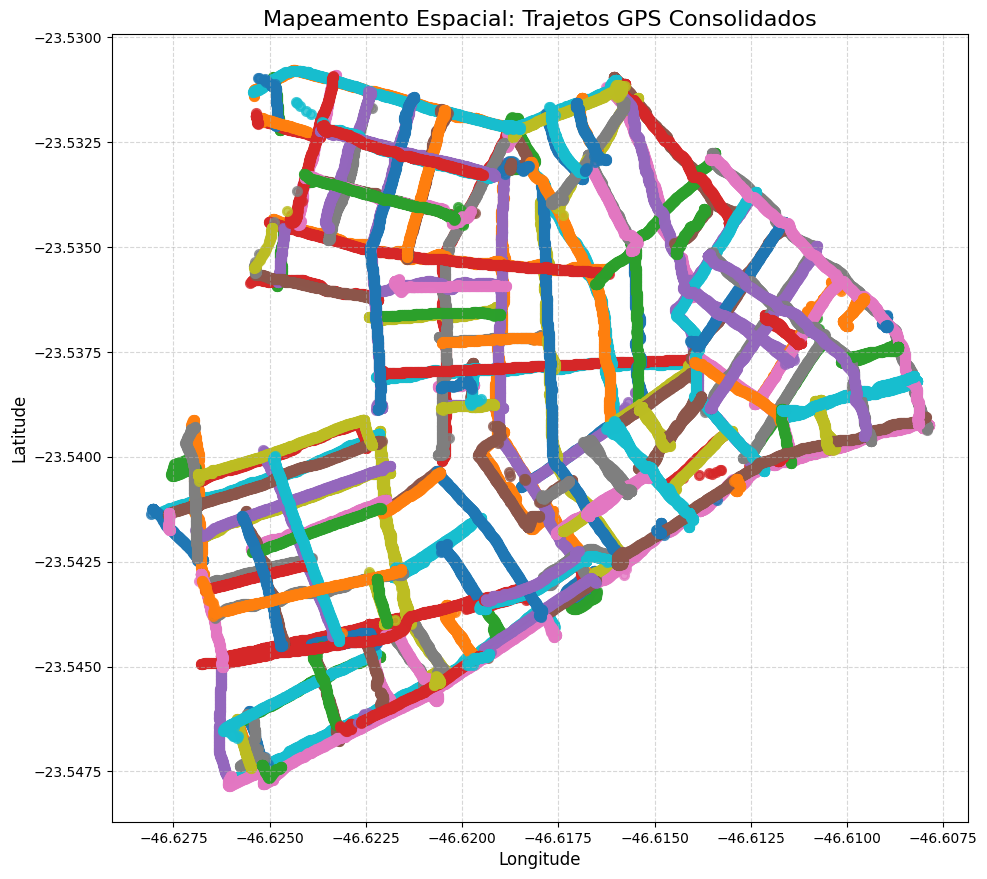

In [ ]:
    # Concatenamos todos os arquivos da lista
gdf_total = pd.concat(lista_gdfs, ignore_index=True)
arquivo_corrompido = "2025-11-11-07-24-55-645.gpkg"

gdf_valido = gdf_total[gdf_total['id_rota'] != arquivo_corrompido]

fig, ax = plt.subplots(figsize=(10, 10))

for rota in gdf_valido['id_rota'].unique():

      gdf_rota = gdf_valido[gdf_valido['id_rota'] == rota]
      gdf_rota.plot(ax=ax, linewidth=2, alpha=0.8)

# 5. Estética Profissional para o Relatório Final
plt.title('Mapeamento Espacial: Trajetos GPS Consolidados', fontsize=16)
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Semana 3
1. Detecção de Curvas: Usar o giroscópio para encontrar as curvas mais agudas e cruzar o horário desses picos com os dados de GPS para validação.


2. Faixas de Pedestre: Aplicar seus conhecimentos de pré-processamento de imagens junto com o OpenCV e a Transformada de Hough para detectar as linhas retas das faixas pintadas no chão.

In [ ]:
gdf_total['dado_rota'] = gdf_total['id_rota'].str.replace('.gpkg', '', regex=False)

In [ ]:
# plota todas as rotas em comum (graças a deus todas)
rotas_giro = set(df_giro['dado_rota'].unique())
rotas_gps = set(gdf_total['dado_rota'].unique())
rotas_em_comum = rotas_giro & rotas_gps
print(f"{len(rotas_em_comum)} rotas em comum")
print(sorted(rotas_em_comum))

216 rotas em comum
['2025-11-09-07-23-58-838', '2025-11-09-07-24-24-340', '2025-11-09-07-24-50-402', '2025-11-09-07-27-34-253', '2025-11-09-07-27-40-010', '2025-11-09-07-29-43-708', '2025-11-09-07-30-26-637', '2025-11-09-07-32-01-186', '2025-11-09-07-35-01-617', '2025-11-09-07-35-04-181', '2025-11-09-07-53-36-135', '2025-11-09-07-53-43-353', '2025-11-09-07-54-14-452', '2025-11-09-07-54-52-104', '2025-11-09-07-58-09-377', '2025-11-09-07-58-39-775', '2025-11-09-08-08-32-752', '2025-11-09-08-08-46-138', '2025-11-09-08-15-45-642', '2025-11-09-08-20-12-864', '2025-11-09-08-20-13-291', '2025-11-09-08-35-49-563', '2025-11-09-08-35-50-674', '2025-11-09-08-41-49-243', '2025-11-09-08-42-08-971', '2025-11-09-08-42-26-692', '2025-11-09-08-42-28-852', '2025-11-09-08-46-13-168', '2025-11-09-08-46-39-939', '2025-11-09-08-49-19-940', '2025-11-09-08-49-50-968', '2025-11-09-08-50-07-859', '2025-11-09-08-50-10-436', '2025-11-09-09-06-18-570', '2025-11-09-09-06-45-083', '2025-11-09-09-07-17-998', '2025-11

In [ ]:
def plotar_curvas_rota(nome_rota, df_giro_total, gdf_total, altura_pico=np.pi/2):
    df_giro_dia = df_giro_total[df_giro_total['dado_rota'] == nome_rota].copy()
    gdf_rota = gdf_total[gdf_total['dado_rota'] == nome_rota].copy()

    if df_giro_dia.empty or gdf_rota.empty:
        print(f"Nenhum dado encontrado para a rota '{nome_rota}'. Rotas disponíveis:")
        print(df_giro_total['dado_rota'].unique())
        return

    picos, _ = scipy.signal.find_peaks(df_giro_dia['axis_x'].values, height=altura_pico)
    vales, _ = scipy.signal.find_peaks(-df_giro_dia['axis_x'].values, height=altura_pico)
    linha_curva = np.concatenate((picos, vales))
    linha_curva.sort()

    print(f"Rota: {nome_rota}")
    print(f"Curvas detectadas: {len(linha_curva)} (Picos: {len(picos)}, Vales: {len(vales)})")

    if len(linha_curva) == 0:
        print("Nenhuma curva detectada com o limiar atual.")
        return

    # CORREÇÃO: giroscópio está em horário local (UTC-3), GPS está em UTC real
    tempo_giro_oficial = (
        pd.to_datetime(df_giro_dia['datetime_utc']) - pd.Timedelta(hours=3)
    ).astype('int64')
    timestamps_curvas = tempo_giro_oficial.iloc[linha_curva].values

    # CORREÇÃO: timestamp_gps vem em milissegundos, precisa virar nanossegundos
    tempo_gps_nano = gdf_rota['timestamp_gps'].astype('int64') * 1_000_000

    lat_curvas = []
    lon_curvas = []
    for t in timestamps_curvas:
        indice_mais_proximo = (tempo_gps_nano - t).abs().idxmin()
        ponto_exato = gdf_rota.loc[indice_mais_proximo, 'geometry']
        lat_curvas.append(ponto_exato.y)
        lon_curvas.append(ponto_exato.x)

    plt.figure(figsize=(10, 10))
    plt.plot(gdf_rota.geometry.x, gdf_rota.geometry.y,
             label='Caminho Percorrido', color='#00B4D8', linewidth=2, alpha=0.8)
    plt.plot(lon_curvas, lat_curvas, 'o', color='red',
             markersize=10, label='Curvas Detectadas')
    plt.plot(gdf_rota.geometry.x.iloc[0], gdf_rota.geometry.y.iloc[0],
             'o', color='#FFD166', markersize=12, label='Início')
    plt.plot(gdf_rota.geometry.x.iloc[-1], gdf_rota.geometry.y.iloc[-1],
             's', color='#FF5285', markersize=12, label='Fim')

    plt.title(f'Mapeamento Geográfico de Curvas - Rota {nome_rota}', fontsize=16, color='#2C3E50')
    plt.xlabel('Longitude', fontsize=12)
    plt.ylabel('Latitude', fontsize=12)
    plt.legend(loc='best')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

Rota: 2025-11-09-09-23-40-580
Curvas detectadas: 2 (Picos: 0, Vales: 2)


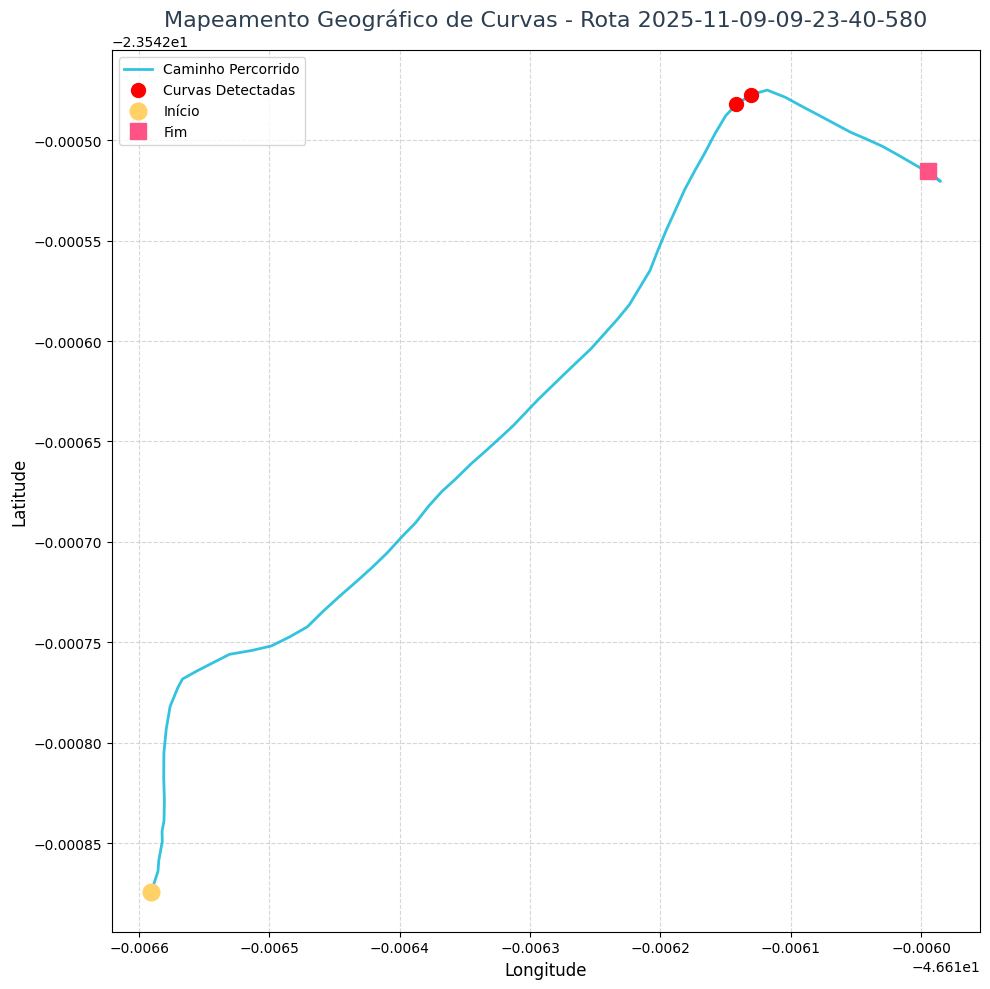

In [ ]:
plotar_curvas_rota('2025-11-09-09-23-40-580', df_giro, gdf_total, altura_pico=1
                   )

In [ ]:
# --- CÉLULA: plotar N rotas aleatórias com um altura_pico fixo ---
import random

def plotar_rotas_aleatorias(df_giro_total, gdf_total, n=10, altura_pico=1, seed=None):
    """
    Sorteia `n` rotas que existem tanto no giroscópio quanto no GPS
    e chama plotar_curvas_rota para cada uma, usando o mesmo altura_pico.
    """
    rotas_giro = set(df_giro_total['dado_rota'].unique())
    rotas_gps = set(gdf_total['dado_rota'].unique())
    rotas_em_comum = list(rotas_giro & rotas_gps)

    if len(rotas_em_comum) == 0:
        print("Nenhuma rota em comum entre giroscópio e GPS.")
        return []

    n = min(n, len(rotas_em_comum))

    if seed is not None:
        random.seed(seed)

    rotas_sorteadas = random.sample(rotas_em_comum, n)

    print(f"Rotas sorteadas ({n}):")
    for r in rotas_sorteadas:
        print(f"  - {r}")
    print()

    for nome_rota in rotas_sorteadas:
        plotar_curvas_rota(nome_rota, df_giro_total, gdf_total, altura_pico=altura_pico)

    return rotas_sorteadas

Rotas sorteadas (10):
  - 2025-11-16-08-46-54-507
  - 2025-11-09-09-41-04-399
  - 2025-11-09-08-41-49-243
  - 2025-11-09-09-48-14-582
  - 2025-11-10-07-29-43-918
  - 2025-11-11-09-55-36-414
  - 2025-11-16-09-14-50-990
  - 2025-11-10-07-59-21-443
  - 2025-11-09-09-14-46-632
  - 2025-11-16-07-54-46-523

Rota: 2025-11-16-08-46-54-507
Curvas detectadas: 22 (Picos: 11, Vales: 11)


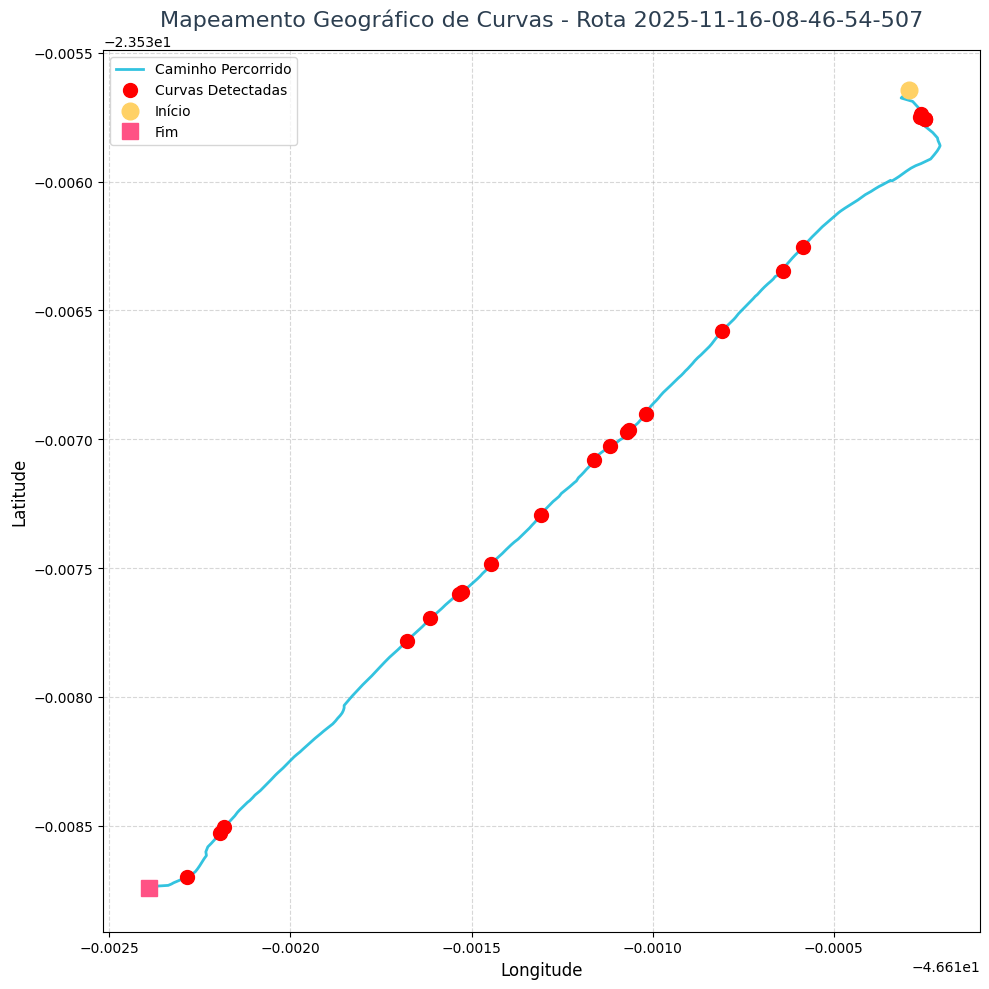

Rota: 2025-11-09-09-41-04-399
Curvas detectadas: 14 (Picos: 7, Vales: 7)


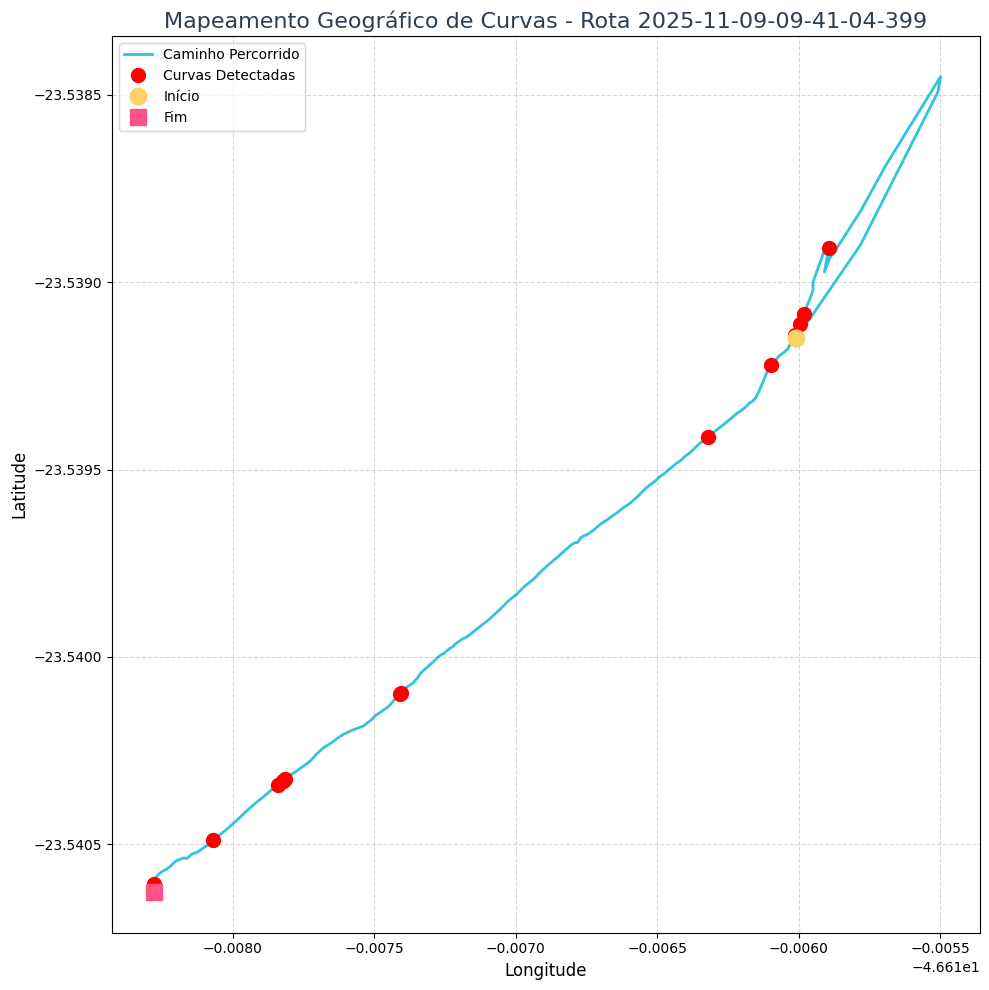

Rota: 2025-11-09-08-41-49-243
Curvas detectadas: 2 (Picos: 2, Vales: 0)


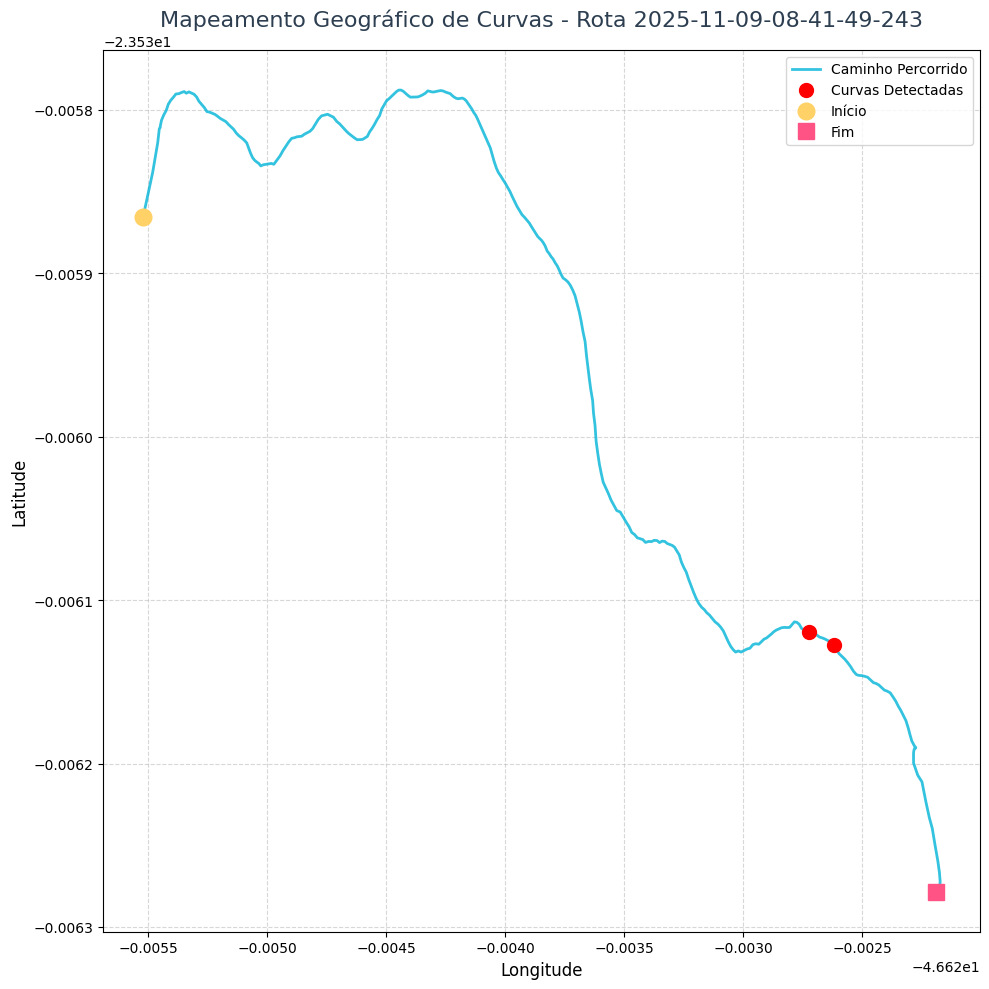

Rota: 2025-11-09-09-48-14-582
Curvas detectadas: 34 (Picos: 14, Vales: 20)


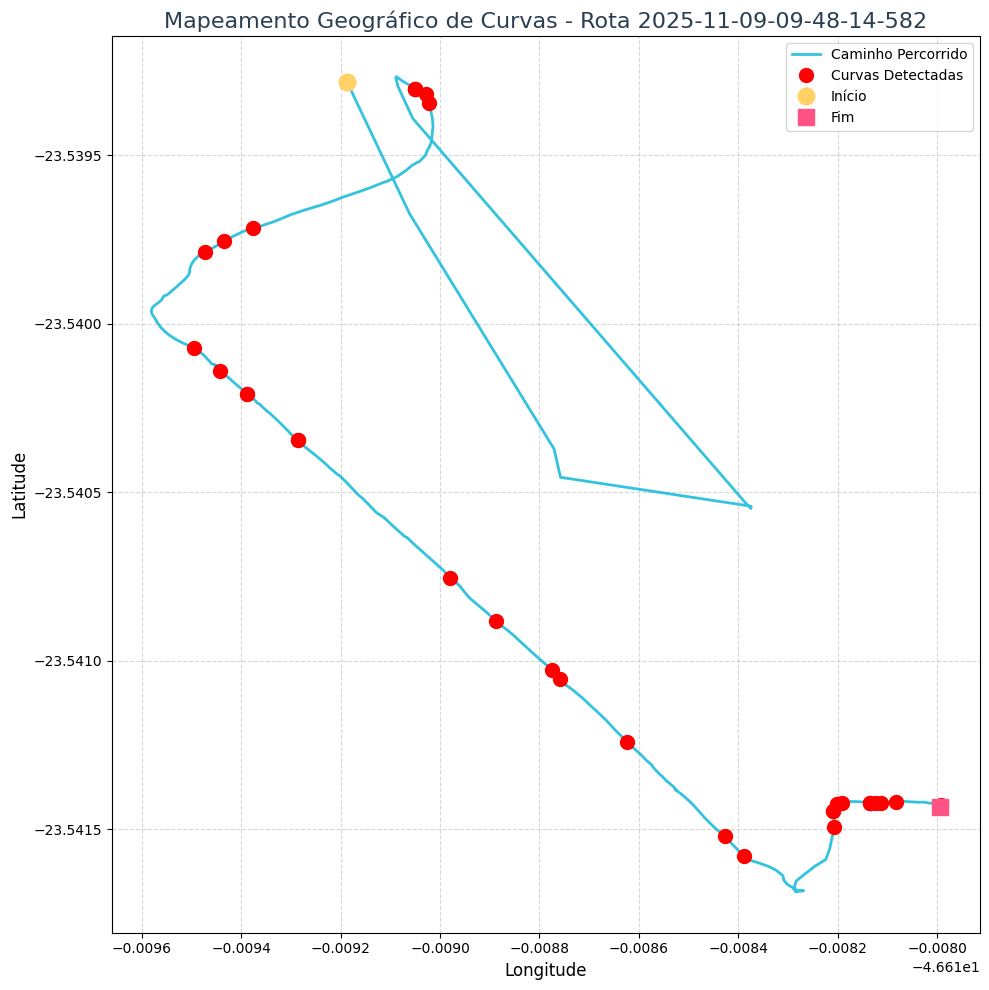

Rota: 2025-11-10-07-29-43-918
Curvas detectadas: 24 (Picos: 8, Vales: 16)


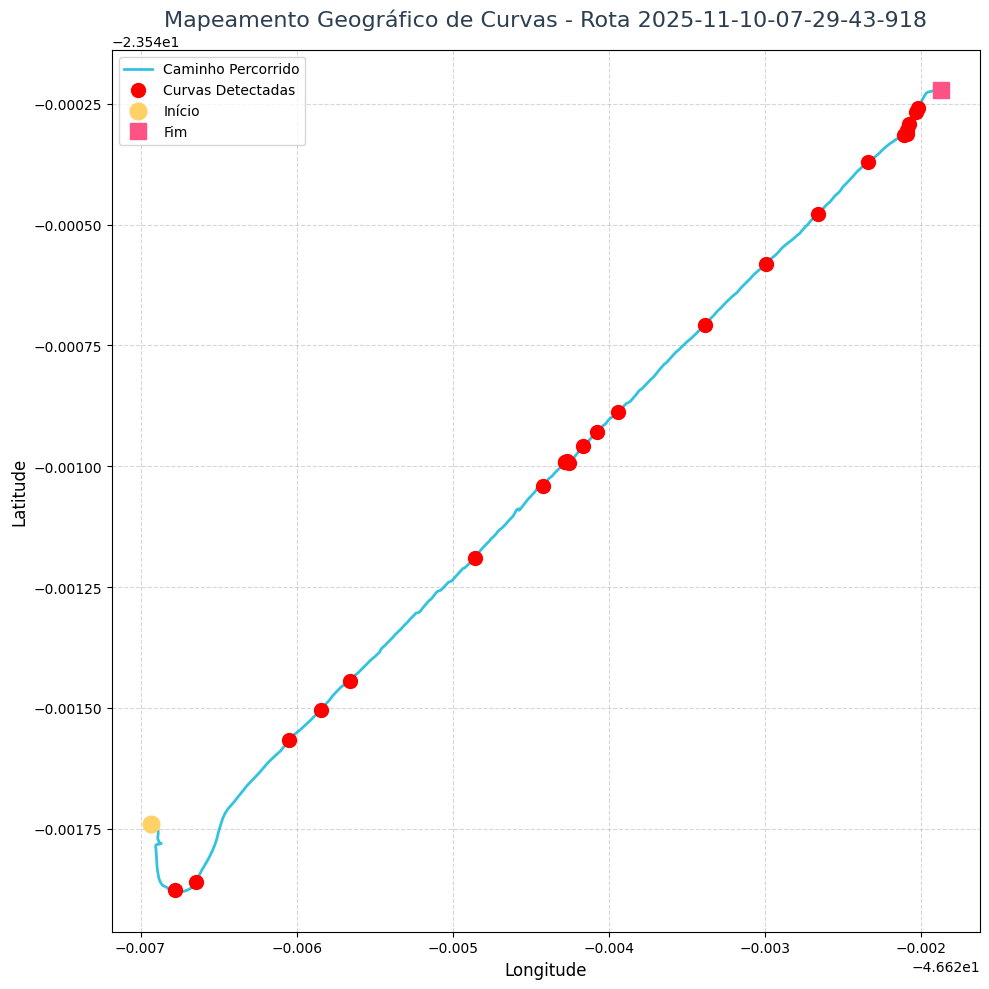

Rota: 2025-11-11-09-55-36-414
Curvas detectadas: 2 (Picos: 2, Vales: 0)


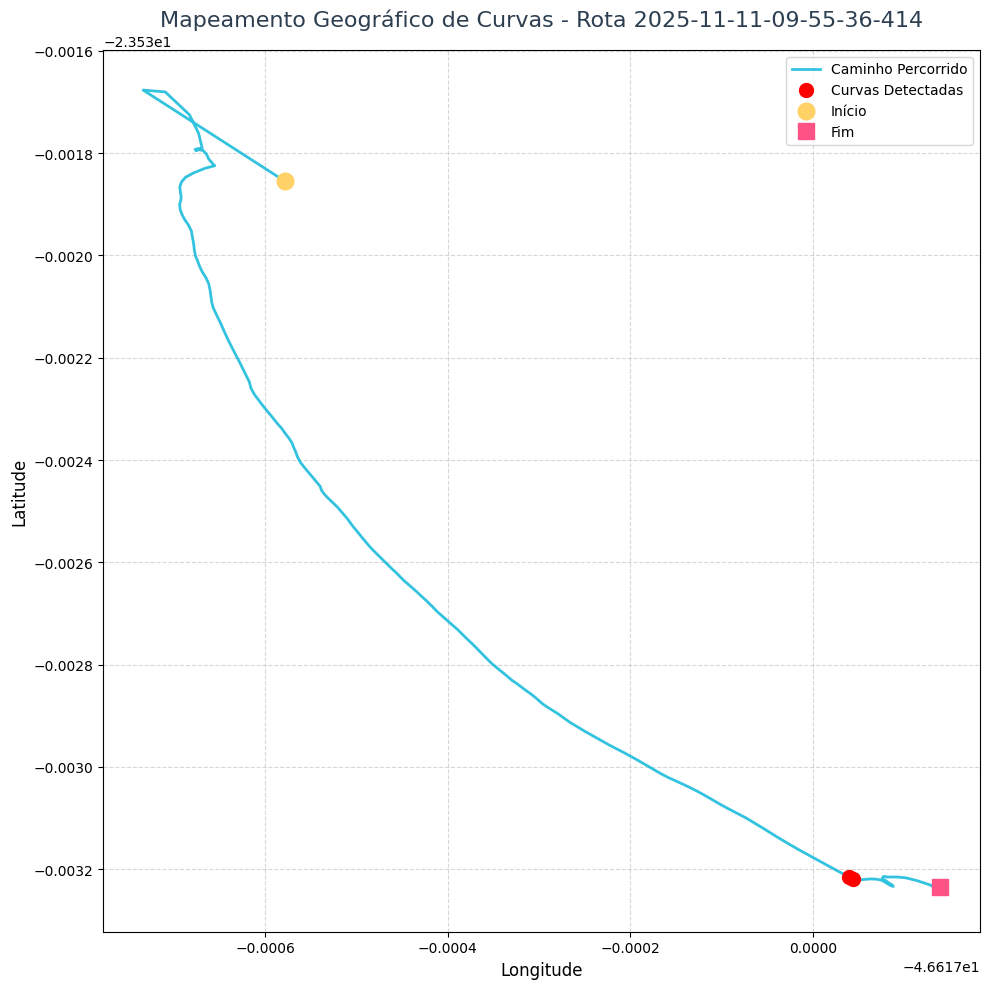

Rota: 2025-11-16-09-14-50-990
Curvas detectadas: 133 (Picos: 73, Vales: 60)


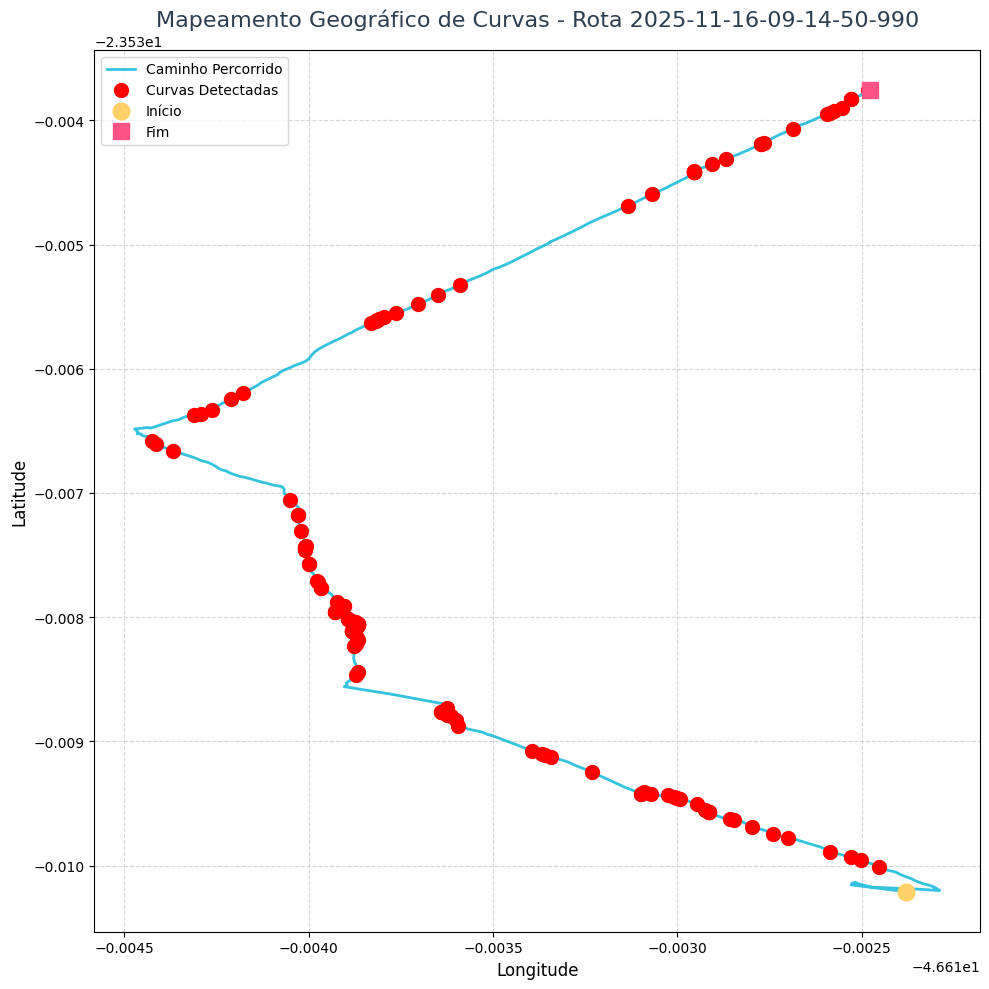

Rota: 2025-11-10-07-59-21-443
Curvas detectadas: 3 (Picos: 3, Vales: 0)


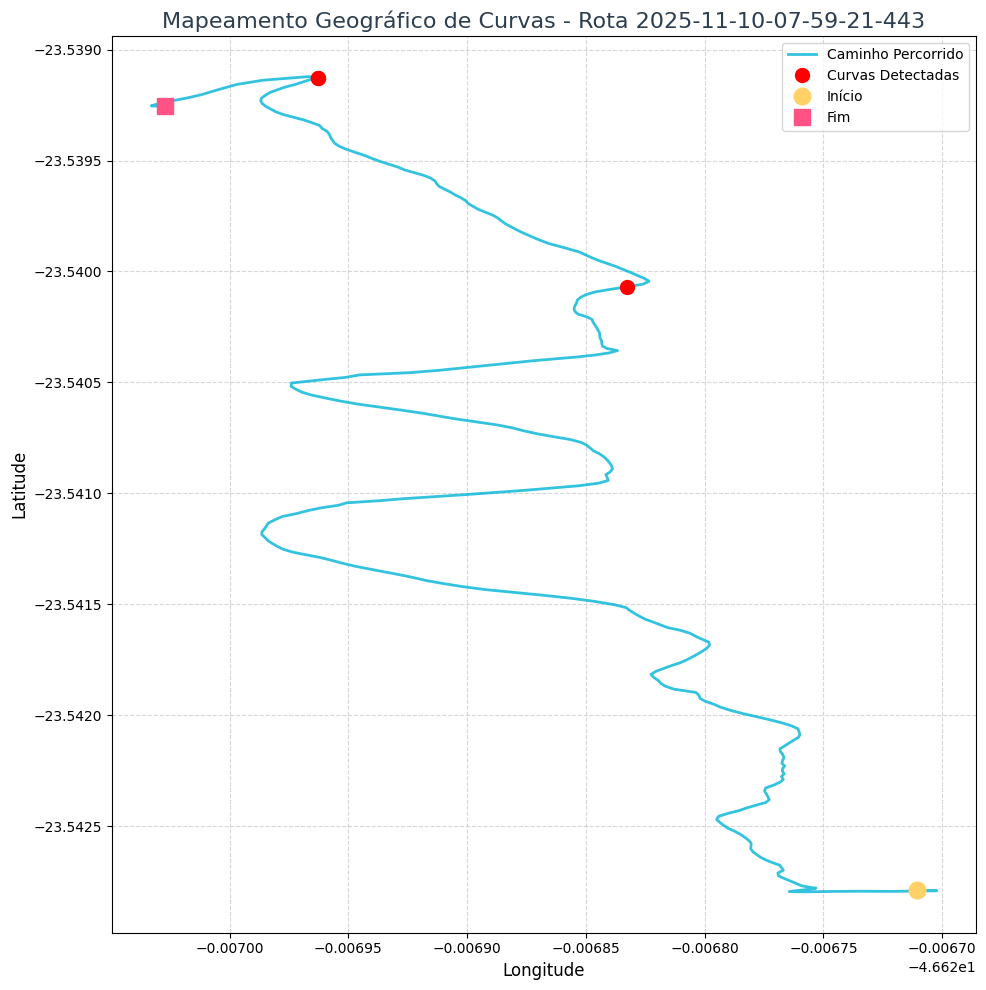

Rota: 2025-11-09-09-14-46-632
Curvas detectadas: 3 (Picos: 1, Vales: 2)


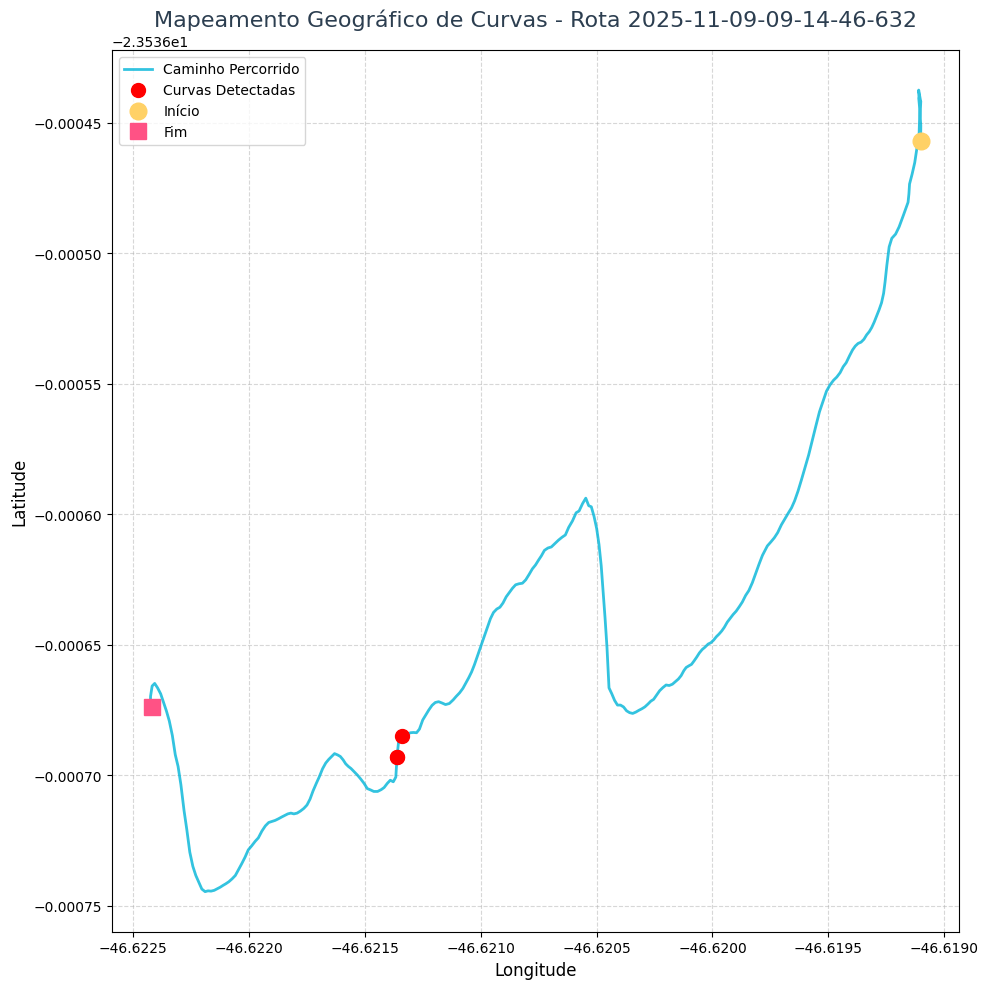

Rota: 2025-11-16-07-54-46-523
Curvas detectadas: 0 (Picos: 0, Vales: 0)
Nenhuma curva detectada com o limiar atual.


In [ ]:
# --- USO ---
rotas_testadas = plotar_rotas_aleatorias(df_giro, gdf_total, n=10, altura_pico=1, seed=47)

In [ ]:
def comparar_escalas_rota(nome_rota, gdf_total, arquivo_corrompido=None):
    """
    Plota a mesma rota de duas formas:
    1. Zoom na rota (como plotar_curvas_rota faz) - ruído bem visível.
    2. Com a mesma extensão/aspecto do plot consolidado - ruído "escondido".
    """
    gdf_rota = gdf_total[gdf_total['dado_rota'] == nome_rota].copy()
    if gdf_rota.empty:
        print(f"Rota '{nome_rota}' não encontrada.")
        return

    # extensão de TODAS as rotas válidas, pra usar como referência de escala
    gdf_valido = gdf_total.copy()
    if arquivo_corrompido:
        gdf_valido = gdf_valido[gdf_valido['id_rota'] != arquivo_corrompido]

    xmin, ymin, xmax, ymax = gdf_valido.total_bounds

    fig, axes = plt.subplots(1, 2, figsize=(16, 8))

    # --- Painel 1: zoom só na rota (escala "individual") ---
    gdf_rota.plot(ax=axes[0], linewidth=2, alpha=0.8, color='#00B4D8')
    axes[0].set_title(f'Zoom na rota\n(escala individual)', fontsize=13)
    axes[0].set_xlabel('Longitude')
    axes[0].set_ylabel('Latitude')
    axes[0].grid(True, linestyle='--', alpha=0.5)
    axes[0].set_aspect('equal')

    # --- Painel 2: mesma rota, mas com a extensão de TODAS as rotas ---
    gdf_rota.plot(ax=axes[1], linewidth=2, alpha=0.8, color='#00B4D8')
    axes[1].set_xlim(xmin, xmax)
    axes[1].set_ylim(ymin, ymax)
    axes[1].set_title(f'Mesma rota\n(escala consolidada - como no plot com todas as rotas)', fontsize=13)
    axes[1].set_xlabel('Longitude')
    axes[1].set_ylabel('Latitude')
    axes[1].grid(True, linestyle='--', alpha=0.5)
    axes[1].set_aspect('equal')

    fig.suptitle(f'Rota: {nome_rota}', fontsize=15)
    plt.tight_layout()
    plt.show()

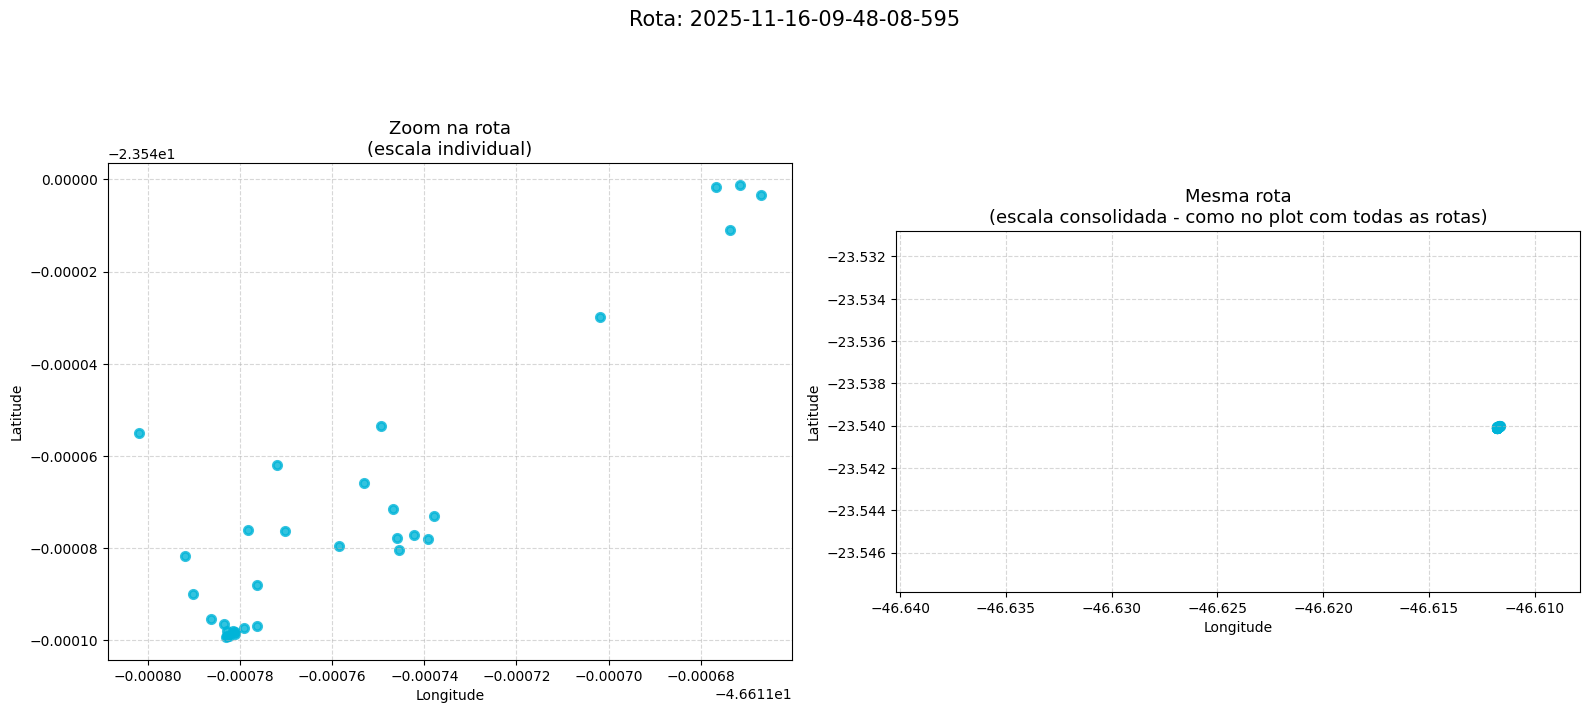

In [ ]:
# --- USO ---
comparar_escalas_rota('2025-11-16-09-48-08-595', gdf_total,
                       arquivo_corrompido="2025-11-11-07-24-55-645")

In [ ]:
# --- CÉLULA: comparar escalas em N rotas aleatórias ---
import random

def comparar_escalas_rotas_aleatorias(gdf_total, n=10, arquivo_corrompido=None, seed=None):
    """
    Sorteia `n` rotas do gdf_total e chama comparar_escalas_rota para cada uma.
    """
    gdf_valido = gdf_total.copy()
    if arquivo_corrompido:
        gdf_valido = gdf_valido[gdf_valido['id_rota'] != arquivo_corrompido]

    rotas_disponiveis = list(gdf_valido['dado_rota'].unique())

    if len(rotas_disponiveis) == 0:
        print("Nenhuma rota disponível.")
        return []

    n = min(n, len(rotas_disponiveis))

    if seed is not None:
        random.seed(seed)

    rotas_sorteadas = random.sample(rotas_disponiveis, n)

    print(f"Rotas sorteadas ({n}):")
    for r in rotas_sorteadas:
        print(f"  - {r}")
    print()

    for nome_rota in rotas_sorteadas:
        comparar_escalas_rota(nome_rota, gdf_total, arquivo_corrompido=arquivo_corrompido)

    return rotas_sorteadas

In [ ]:
# --- USO ---
rotas_testadas = comparar_escalas_rotas_aleatorias(
    gdf_total,
    n=100,
    arquivo_corrompido="2025-11-11-07-24-55-645",
    seed=43333
)

Output hidden; open in https://colab.research.google.com to view.

# ignorar o que ta abaixo disso
